# Active subspaces of the lift of a shape-perturbed NACA 4412 airfoil (unsteady RANS, OpenFOAM)

Stored data from

M. Tezzele, N. Demo, G. Stabile, A. Mola and G. Rozza, *Enhancing CFD predictions in shape design problems by
model and parameter space reduction*, Advanced Modeling and Simulation in Engineering Sciences 7:40, 2020.
[doi:10.1186/s40323-020-00177-y](https://doi.org/10.1186/s40323-020-00177-y)

Mathematics Area, mathLab, SISSA, International School of Advanced Studies, via Bonomea 265, 34136 Trieste,
Italy (all authors).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 4412                       # the only seed: every bootstrap and fold split below draws from it
t_start = time.perf_counter()
warnings.simplefilter('once', ac.ValidityWarning)
warnings.showwarning = lambda msg, cat, *args, **kw: print(f'{cat.__name__}: {msg}')   # message only

## Summary

Tezzele et al. ran 170 unsteady RANS simulations (OpenFOAM, Spalart–Allmaras, 30 s of flow) past a NACA 4412
airfoil whose upper and lower surfaces are perturbed by ten weights of five Hicks–Henne-type shape functions,
and published the weights and the lift-coefficient histories; this notebook takes as quantity of interest the
mean lift coefficient over the last 5 s of each run (a choice made here, not in the paper) and estimates its
active subspace with the global quadratic estimator (QPHD) from the 170 runs. The eigenvalues have their
largest gap after the second ($\lambda_2/\lambda_3$ = 11.14 against $\lambda_1/\lambda_2$ = 4.12), and a
quadratic in the two active variables predicts the mean lift with leave-one-out $R^2$ 0.9708 (0.9647 when
the subspace is refitted in each of 10 folds), so the data set has a two-dimensional active subspace
spanned mainly by the upper-surface weights $c_3$, $c_4$ and the lower-surface weights $d_3$, $d_4$. The paper's
dynamic active subspace at 6, 10, 14 and 18 s (Figs. 6–9) is reproduced from the same runs with the
authors' method, local linear gradients on their 70 training runs ($|w_1 \cdot w_{fig}|$ = 0.996–1.000), after noting that the figures' $d$ axis is the stored
$-d$, which reverses the paper's thickness reading of the $d_3$, $d_4$ weights.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients the matrix is estimated from values: the global quadratic estimator (QPHD) fits
$f \approx c + \mathbf{b}^\top\mathbf{x} + \tfrac12 \mathbf{x}^\top \mathbf{A}\mathbf{x}$ by least squares and
uses the gradient $\mathbf{b} + \mathbf{A}\mathbf{x}$ of the fit; local linear gradients fit a linear model to
the nearest neighbours of each point. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension
Reduction in Parameter Studies*, SIAM, 2015, [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Flow** (paper, pp. 3 and 9). Unsteady incompressible Navier–Stokes equations (Eq. 3, p. 3) with
Reynolds averaging and the Spalart–Allmaras one-equation turbulence model, solved with OpenFOAM's PIMPLE
algorithm (`pimpleFoam`) on a two-dimensional domain around a NACA 4412 airfoil at 0° angle of attack:
inlet velocity $u_{in}$ = 1 m/s, kinematic viscosity $\nu$ = 2e−5 m²/s, chord 1 m, so Re = 50,000 (p. 9).
The reference mesh has 46,500 hexahedral cells (p. 8); the domain is sketched in Fig. 3 (p. 10). Time step
$\Delta t$ = 1e−3 s, second-order backward differences in time, second-order upwind convection; each run
covers $T_s$ = 30 s from an impulsive start, which "is sufficient to reach a solution which is reasonably
close to the steady state one" (p. 9). One simulated second cost about 1508 CPU s on one core of an Intel
Xeon E5-2640, about 45,000 CPU s for a 30 s run (p. 14). The undeformed airfoil gives
$C_L$ = 0.355 (p. 9); it is not among the 170 runs.

**Shape parameterization** (Eqs. 4–5, p. 4). With $\bar y_u$, $\bar y_l$ the upper and lower ordinates of
the NACA 4412,

$$y_u = \bar y_u + \sum_{i=1}^5 c_i\, r_i, \qquad y_l = \bar y_l - \sum_{i=1}^5 d_i\, r_i,$$

and the mesh follows by radial-basis-function morphing (Wendland kernel, $r_{RBF}$ = 0.1 m, $r_{out}$ = 7 m;
pp. 4–5 and 9). The paper takes the shape functions $r_i$ from Hicks and Henne (its ref. 24) and plots them
in Fig. 1 without formulas. The authors' solver (`MORTECH.C` in their repository) codes them, with
$\xi = x/\text{chord}$ measured from the leading edge, as

$$r_1 = \sqrt{\xi}\,(1-\xi)\,e^{-15\xi},\quad r_2 = \sin^3(\pi\xi^{0.25}),\quad r_3 = \sin^3(\pi\xi^{0.757}),\quad
r_4 = \sin^3(\pi\xi^{1.357}),\quad r_5 = \sqrt{\xi}\,(1-\xi)\,e^{-10\xi},$$

times the chord (1 m). Positive $c_i$ raise the upper surface; positive $d_i$ lower the lower surface, so
equal $c_i$ and $d_i$ thicken the section and $c_i$ with $-d_i$ shift it (camber).

**Inputs** ($m$ = 10): the weights $c_1,\dots,c_5$ and $d_1,\dots,d_5$, each in $[0, 0.03]$, the box
$D = [0, 0.03]^{10}$ (p. 9). They are dimensionless multipliers of $r_i$, which is in chords. The paper
does not say how the points were drawn in $D$; the checks below find them consistent with independent
uniform draws.

**Quantity of interest.** The stored output of each run is the lift coefficient $C_L(t)$ at every time step,
30,000 values. The paper analyses $C_L$ at fixed times (6, 10, 14, 18 s for the active subspaces; up to
20 s and DMD forecasts to 30 s for the regressions, pp. 11–16). **This notebook's scalar** is the mean
lift over the last 5 s, $\bar C_L = \frac{1}{5000}\sum_{25 < t_k \le 30\,\text{s}} C_L(t_k)$: the rule
drops the first 25 s as start-up transient. It is this data set's choice; a later cell shows its effect.

**Gradients.** None: the runs give values only, and finite differences would cost $m + 1$ = 11 runs of about 45,000 CPU s
per gradient. The subspace is estimated from values (QPHD), with local linear gradients and the linear fit as
checks.

In [2]:
# The 10 inputs, in the column order of shape_inputs.csv: weight, surface, shape function, range
# (paper, Eqs. 4-5 on p. 4 and the box D = [0, 0.03]^10 on p. 9).
NAMES = [f'c{i}' for i in range(1, 6)] + [f'd{i}' for i in range(1, 6)]
LOWER, UPPER = np.zeros(10), np.full(10, 0.03)
print(f"{'input':6s} {'surface':8s} {'adds':12s} {'range':14s} units")
for i, n in enumerate(NAMES):
    surf, sign = ('upper', '+') if n[0] == 'c' else ('lower', '-')
    print(f"{n:6s} {surf:8s} {sign + ' ' + n + ' r' + n[1]:12s} [{LOWER[i]:.0f}, {UPPER[i]:.2f}]    1 (r_i in chords)")

# The five shape functions, as coded in the authors' solver (MORTECH.C), xi = x/chord from the leading edge.
xi = np.linspace(0, 1, 100001)
R = {1: np.sqrt(xi) * (1 - xi) * np.exp(-15 * xi), 2: np.sin(np.pi * xi**0.25)**3,
     3: np.sin(np.pi * xi**0.757)**3, 4: np.sin(np.pi * xi**1.357)**3,
     5: np.sqrt(xi) * (1 - xi) * np.exp(-10 * xi)}
print('\nshape function   max r_i   at xi   largest offset 0.03*max (chords)')
for k, r in R.items():
    print(f'r{k}               {r.max():.4f}    {xi[r.argmax()]:.3f}   {0.03 * r.max():.5f}')

input  surface  adds         range          units
c1     upper    + c1 r1      [0, 0.03]    1 (r_i in chords)
c2     upper    + c2 r2      [0, 0.03]    1 (r_i in chords)
c3     upper    + c3 r3      [0, 0.03]    1 (r_i in chords)
c4     upper    + c4 r4      [0, 0.03]    1 (r_i in chords)
c5     upper    + c5 r5      [0, 0.03]    1 (r_i in chords)
d1     lower    - d1 r1      [0, 0.03]    1 (r_i in chords)
d2     lower    - d2 r2      [0, 0.03]    1 (r_i in chords)
d3     lower    - d3 r3      [0, 0.03]    1 (r_i in chords)
d4     lower    - d4 r4      [0, 0.03]    1 (r_i in chords)
d5     lower    - d5 r5      [0, 0.03]    1 (r_i in chords)

shape function   max r_i   at xi   largest offset 0.03*max (chords)
r1               0.1072    0.031   0.00322
r2               1.0000    0.062   0.03000
r3               1.0000    0.400   0.03000
r4               1.0000    0.600   0.03000
r5               0.1292    0.045   0.00388


$r_2$, $r_3$, $r_4$ reach 1 (at $\xi$ = 0.062, 0.400, 0.600), while $r_1$ and $r_5$ peak at 0.1072 and
0.1292 near the leading edge, so the largest offset the weights $c_1, c_5, d_1, d_5$ can make is 0.00322 and
0.00388 chords against 0.03 for the other six. This explains much of what the paper finds about those four
weights (p. 11).

## Load the data

Two files, converted losslessly by `convert_data.py` from the authors' GitHub repository
(github.com/mtezzele/MORtech-2019-Special-Issue): `shape_inputs.csv` holds the 10 weights of the 170 runs
(the lower-surface weights with the sign of Eq. 5; the repository stores $-d_i$) and a flag for the 70 runs
the paper used for training; `lift_series.npz` holds the 170 × 30,000 lift histories, coded as integer
mantissas and powers of ten that decode to the stored values (DATA.md).

In [3]:
XA = np.loadtxt('shape_inputs.csv', delimiter=',')         # 170 x 11: c1..c5, d1..d5, training flag
X, TRAIN = XA[:, :10], XA[:, 10].astype(bool)
with np.load('lift_series.npz') as z:                       # lossless 7-digit encoding (DATA.md)
    LIFT = np.cumsum(z['mantissa_diff'], axis=1, dtype=np.int64) / 10.0 ** z['scale']
DT = 1e-3
T = DT * np.arange(1, LIFT.shape[1] + 1)                    # column k holds time step k + 1
M, m = X.shape
print('inputs', X.shape, ' lift histories', LIFT.shape, ' training runs', TRAIN.sum(),
      f' time {T[0]:.3f}-{T[-1]:.3f} s')

inputs (170, 10)  lift histories (170, 30000)  training runs 70  time 0.001-30.000 s


### Checks of the stored data

Before any analysis: are these plausibly the paper's simulation outputs? The next cell checks the design
(range, duplicates, uniformity, strata), looks for the one sample the paper prints (Fig. 4 caption, p. 10),
and characterises the histories (start-up spikes, smoothness).

In [4]:
print('inside D = [0, 0.03]^10:', bool(np.all((X >= LOWER) & (X <= UPPER))),
      f' min {X.min():.3g}, max {X.max():.5f}')
print('duplicate input rows:', M - len(np.unique(X, axis=0)))
print('column means (uniform 0.015):', np.round(X.mean(0), 4))
print('column sd (uniform 0.00866):  ', np.round(X.std(0, ddof=1), 4))
ks = [stats.kstest(X[:, j], 'uniform', args=(0, 0.03)).pvalue for j in range(m)]
print(f'Kolmogorov-Smirnov p against U(0, 0.03): {min(ks):.3f}-{max(ks):.3f}')
kurt = stats.kurtosis(X, axis=0, fisher=False)              # normalized 4th moment; uniform 1.8
print('KS p per input:              ', np.round(ks, 3))
print('normalized kurtosis per input:', np.round(kurt, 2), ' (uniform 1.8)')
null = stats.kurtosis(np.random.default_rng(SEED).uniform(size=(20000, M)), axis=1, fisher=False)
print(f'kurtosis of {M} independent uniform draws (20000 replicates): 2.5 % quantile {np.quantile(null, 0.025):.2f}; '
      f'share at or below the smallest column value ({kurt.min():.2f}): {np.mean(null <= kurt.min()):.4f}')
for lab, rows in (('training', TRAIN), ('test', ~TRAIN)):
    k = rows.sum()
    occ = [len(np.unique(np.floor(X[rows, j] / 0.03 * k))) for j in range(m)]
    print(f'{lab} rows ({k}): occupied strata of {k} per input {min(occ)}-{max(occ)}; '
          f'independent draws expect {k * (1 - (1 - 1 / k)**k):.1f}, a Latin hypercube {k}')

mu_fig4 = np.array([0.0071, 0.0229, 0.0015, 0.0015, 0.0087, 0.0107, 0.0033, 0.0130, 0.0247, 0.0280])
swapped = np.hstack([X[:, 5:], X[:, :5]])                  # (d1..d5, c1..c5)
trunc = np.floor(swapped * 1e4) / 1e4
hit = np.where(np.all(np.isclose(trunc, mu_fig4, atol=1e-12), axis=1))[0]
print('rows whose (d, c) truncated to 4 decimals equal the Fig. 4 sample:', hit,
      ' training run:', bool(TRAIN[hit].all()) if len(hit) else None)

big = np.abs(LIFT) > 1
last_big = np.array([np.flatnonzero(b).max() + 1 for b in big])
print(f'start-up spikes: max |C_L| in the first 0.05 s {np.abs(LIFT[:, :50]).max():.1f}; '
      f'last step with |C_L| > 1: {last_big.min()}-{last_big.max()} (median {np.median(last_big):.0f})')
late = LIFT[:, T > 1]
print(f'after 1 s: C_L {late.min():.4f}-{late.max():.4f}; '
      f'largest |second difference| {np.abs(np.diff(late, 2, axis=1)).max():.2e}')
print('identical histories:', M - len(np.unique(LIFT, axis=0)))
k = (T > 5) & (T < 15)
tpk = T[k][LIFT[:, k].argmax(axis=1)]
print(f'time of the largest C_L between 5 and 15 s: {tpk.min():.2f}-{tpk.max():.2f} s (median {np.median(tpk):.2f} s)')

inside D = [0, 0.03]^10: True  min 7.59e-06, max 0.02998
duplicate input rows: 0
column means (uniform 0.015): [0.0154 0.0162 0.0136 0.0158 0.0158 0.0147 0.015  0.0143 0.0159 0.0145]
column sd (uniform 0.00866):   [0.0094 0.0086 0.0088 0.0087 0.0084 0.0088 0.0089 0.0086 0.0088 0.0083]
Kolmogorov-Smirnov p against U(0, 0.03): 0.062-0.969
KS p per input:               [0.201 0.115 0.062 0.162 0.178 0.905 0.969 0.355 0.318 0.541]
normalized kurtosis per input: [1.59 1.86 1.87 1.78 1.91 1.81 1.78 1.85 1.74 1.92]  (uniform 1.8)
kurtosis of 170 independent uniform draws (20000 replicates): 2.5 % quantile 1.65; share at or below the smallest column value (1.59): 0.0037
training rows (70): occupied strata of 70 per input 42-48; independent draws expect 44.4, a Latin hypercube 70
test rows (100): occupied strata of 100 per input 62-68; independent draws expect 63.4, a Latin hypercube 100
rows whose (d, c) truncated to 4 decimals equal the Fig. 4 sample: [1]  training run: True


start-up spikes: max |C_L| in the first 0.05 s 399.0; last step with |C_L| > 1: 10-34 (median 13)


after 1 s: C_L 0.0709-0.4905; largest |second difference| 1.46e-05


identical histories: 0
time of the largest C_L between 5 and 15 s: 9.99-11.20 s (median 11.10 s)


All 170 points lie in $D$, none repeats, and the marginals are consistent with $U(0, 0.03)$
(Kolmogorov–Smirnov p = 0.062–0.969; column sd 0.0083–0.0094 against 0.00866). One column is flatter than
usual: $c_1$ has normalized kurtosis 1.59, below the 2.5 % quantile (1.65) of the kurtosis of 170 independent
uniform draws, of which a share of 0.0037 lie at or below it (its KS p is 0.201); the other nine columns have
kurtosis 1.74–1.92 (uniform 1.8). One low value among ten columns does not change the reading as independent
uniform draws, but the paper does not state its sampler. The design is not a Latin
hypercube: the 70 training points occupy 42–48 of 70 equal strata per input, as independent draws would
(44.4 expected), and the 100 test points 62–68 of 100 (63.4 expected), so the notebook treats the 170 rows
as one Monte Carlo sample of the uniform density on $D$. The sample printed in the Fig. 4 caption is row 1,
a training run, with the lower-surface weights listed first and the values truncated to four decimals.

Each history begins with numerical spikes (|$C_L$| up to 399.0 in the first 0.05 s; the last step with
|$C_L$| > 1 is step 10–34), after which $C_L$ stays in 0.0709–0.4905 and changes smoothly (largest second
difference 1.46e-05 per step). No two histories are identical. Nothing here suggests values that were not
produced by the solver.

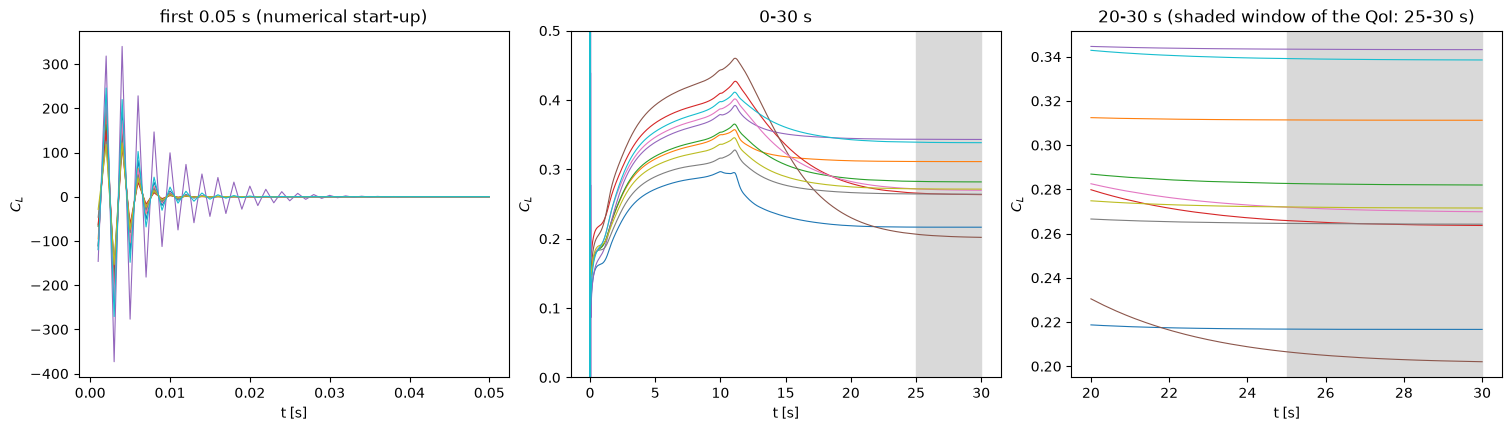

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
show = np.arange(0, M, 17)
k50 = T <= 0.05
for i in show:
    ax[0].plot(T[k50], LIFT[i, k50], lw=0.8)
    ax[1].plot(T, LIFT[i], lw=0.8)
    ax[2].plot(T[T > 20], LIFT[i, T > 20], lw=0.8)
ax[0].set(xlabel='t [s]', ylabel='$C_L$', title='first 0.05 s (numerical start-up)')
ax[1].set(xlabel='t [s]', ylabel='$C_L$', ylim=(0, 0.5), title='0-30 s')
ax[1].axvspan(25, 30, color='0.85', zorder=0)
ax[2].set(xlabel='t [s]', ylabel='$C_L$', title='20-30 s (shaded window of the QoI: 25-30 s)')
ax[2].axvspan(25, 30, color='0.85', zorder=0)
plt.close(fig)
fig

The histories show the start-up described on p. 11: a rise while the flow develops, a peak at 9.99–11.20 s
(median 11.10 s), and a slow approach to a steady value in the last third of the run. The shaded band is the averaging window.

## The quantity of interest: mean lift over 25–30 s

The rule drops every time step with $t \le 25$ s and averages the remaining 5,000. Why 25 s: by then the
start-up peak has decayed in every run (figure above) and the paper's own statement is that 30 s is
"reasonably close to the steady state" (p. 9); a window inside the last 5 s keeps most of the averaging while
staying clear of the slow decay that follows the peak. The cell reports how much is still changing inside
the window.

In [6]:
def window_mean(t0, t1=30.0):
    """Mean C_L over the time steps with t0 < t <= t1 (one value per run)."""
    k = (T > t0 + 1e-9) & (T <= t1 + 1e-9)
    return LIFT[:, k].mean(axis=1)


T0 = 25.0                                    # this data set's rule: drop t <= 25 s, average 25 < t <= 30 s
f = window_mean(T0)
print(f'QoI: mean C_L over 25 < t <= 30 s: {f.min():.4f}-{f.max():.4f}, mean {f.mean():.4f}, sd {f.std(ddof=1):.4f}')
half = np.abs(window_mean(25, 27.5) - window_mean(27.5, 30))
slope = np.polyfit(T[T > T0], LIFT[:, T > T0].T, 1)[0]
print(f'|mean 25-27.5 s - mean 27.5-30 s|: median {np.median(half):.1e}, max {half.max():.4f} (run {half.argmax()})')
print(f'linear trend over 25-30 s: {slope.min():.2e} to {slope.max():.2e} per s; '
      f'|C_L(30 s) - QoI| max {np.abs(LIFT[:, -1] - f).max():.4f}')
print(f'within-window sd of C_L: median {np.median(LIFT[:, T > T0].std(1)):.1e}, max {LIFT[:, T > T0].std(1).max():.4f}')

QoI: mean C_L over 25 < t <= 30 s: 0.0738-0.3960, mean 0.2497, sd 0.0592
|mean 25-27.5 s - mean 27.5-30 s|: median 3.5e-04, max 0.0071 (run 61)
linear trend over 25-30 s: -2.86e-03 to 8.22e-07 per s; |C_L(30 s) - QoI| max 0.0061
within-window sd of C_L: median 2.2e-04, max 0.0042


The mean lift ranges over 0.0738–0.3960 (sd 0.0592). Inside the window the runs are close to steady: the
two halves of the window differ by a median 3.5e-04 and at most 0.0071 (run 61, one of the slowest to
settle), the linear trend is between −2.86e-03 per s and 8.22e-07 per s, and the mean differs from the last
value $C_L$(30 s) by at most 0.0061, small against the spread of the QoI across runs.

## Estimate the active subspace

**Scaling.** Every input is mapped from $[0, 0.03]$ to $[-1, 1]$ (`ac.Uniform`, the same affine map for all
ten), and the density is uniform on the box, as the checks support.

**Estimator.** There are no gradients and $M$ = 170 runs. A full quadratic in 10 inputs has 66 coefficients,
so QPHD has 2.6 runs per coefficient (printed below); it is the main estimator here because, unlike the linear fit,
it gives more than one direction and its quadratic fit is accurate (leave-one-out $R^2$ below). The library
warns that QPHD's identities are exact for Gaussian inputs only; on the uniform box it is used as the average
outer product of the fitted quadratic's gradient. Local linear gradients, the method of the authors'
`dyas.py`, and the linear (OLS) direction are computed as checks. Bootstrap: 500 replicates, seed `SEED`.

In [7]:
space = ac.Uniform(LOWER, UPPER, names=NAMES)      # each input mapped from [0, 0.03] to [-1, 1]
Z = space.to_normalized(X)
n_quad = (m + 1) * (m + 2) // 2
print(f'M = {M} runs, {n_quad} coefficients of a full quadratic: {M / n_quad:.1f} runs per coefficient')

sub0 = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', n=2, nboot=500,
                          bootstrap_vectors=2, rng=SEED, qoi='mean C_L 25-30 s')
sub = ac.orient(sub0, by='covariance', X=X, f=f, columns=2)   # f increases with y1 (and y2)
lam = sub.eigenvalues
print('QPHD eigenvalues:', np.array2string(lam, precision=3))
print('ratios lambda_k/lambda_k+1:', np.round(lam[:-1] / lam[1:], 2))
lo95, hi95 = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
for k in range(4):
    print(f'  lambda_{k + 1} = {lam[k]:.3e}  bootstrap 95% [{lo95[k]:.3e}, {hi95[k]:.3e}]')
r12 = sub.bootstrap_eigenvalues[:, 0] / sub.bootstrap_eigenvalues[:, 1]
r23 = sub.bootstrap_eigenvalues[:, 1] / sub.bootstrap_eigenvalues[:, 2]
r34 = sub.bootstrap_eigenvalues[:, 2] / sub.bootstrap_eigenvalues[:, 3]
for lab, r in (('1/2', r12), ('2/3', r23), ('3/4', r34)):
    print(f'  bootstrap 95% of lambda_{lab}: [{np.percentile(r, 2.5):.2f}, {np.percentile(r, 97.5):.2f}]')
print('mean bootstrap subspace distance, k = 1..4:', np.round(sub.bootstrap_distances.mean(0)[:4], 3))
print('left-out eigenvalue share sum_{j>k} lambda_j / sum lambda, k = 1..3:',
      np.round([lam[k:].sum() / lam.sum() for k in (1, 2, 3)], 4))

M = 170 runs, 66 coefficients of a full quadratic: 2.6 runs per coefficient


QPHD eigenvalues: [1.331e-02 3.231e-03 2.900e-04 6.615e-05 4.466e-05 1.993e-05 1.399e-05
 6.838e-06 3.081e-06 2.346e-06]
ratios lambda_k/lambda_k+1: [ 4.12 11.14  4.38  1.48  2.24  1.42  2.05  2.22  1.31]
  lambda_1 = 1.331e-02  bootstrap 95% [1.222e-02, 1.428e-02]
  lambda_2 = 3.231e-03  bootstrap 95% [2.849e-03, 3.859e-03]
  lambda_3 = 2.900e-04  bootstrap 95% [1.986e-04, 5.706e-04]
  lambda_4 = 6.615e-05  bootstrap 95% [5.754e-05, 2.657e-04]
  bootstrap 95% of lambda_1/2: [3.49, 4.58]
  bootstrap 95% of lambda_2/3: [5.81, 16.73]
  bootstrap 95% of lambda_3/4: [1.26, 6.35]
mean bootstrap subspace distance, k = 1..4: [0.05  0.089 0.368 0.794]
left-out eigenvalue share sum_{j>k} lambda_j / sum lambda, k = 1..3: [0.2165 0.0263 0.0092]


The eigenvalues fall from 1.331e-02 and 3.231e-03 to 2.900e-04: the largest ratio is
$\lambda_2/\lambda_3$ = 11.14 (bootstrap 95 % interval 5.81–16.73), against $\lambda_1/\lambda_2$ = 4.12
(3.49–4.58) and $\lambda_3/\lambda_4$ = 4.38 (1.26–6.35). The mean bootstrap subspace distance is 0.05 for
$n$ = 1 and 0.089 for $n$ = 2, then 0.368 for $n$ = 3. The eigenvalues beyond the second hold 0.0263 of the
total, those beyond the first 0.2165.

In [8]:
# Two other estimators on the same data: local linear gradients (as in the authors' dyas.py, which
# used ATHENA's local-linear method) and the global linear fit.
grads_ll = ac.local_linear_gradients(X=X, f=f, space=space)
sub_ll = ac.active_subspace(grads=grads_ll, estimator='as', n=2)
sub_ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1)
lam_ll = sub_ll.eigenvalues
W2q = sub.W[:, :2]
print('local linear: ratios', np.round(lam_ll[:4] / lam_ll[1:5], 2),
      f' |w1_LL . w1_QPHD| {abs(sub_ll.W[:, 0] @ sub.W[:, 0]):.3f},'
      f' distance of the 2-D subspaces {np.linalg.norm(W2q.T @ sub_ll.W[:, 2:], 2):.3f}')
w_ols = sub_ols.W[:, 0]
print(f'OLS direction: |w_OLS . w1| {abs(w_ols @ sub.W[:, 0]):.3f}, '
      f'norm of its projection on span(w1, w2) {np.linalg.norm(W2q.T @ w_ols):.3f}')
warnings.simplefilter('ignore', ac.ValidityWarning)    # the two assumption warnings are shown above; not repeated

local linear: ratios [11.11  2.43  1.08  1.19]  |w1_LL . w1_QPHD| 0.950, distance of the 2-D subspaces 0.339
OLS direction: |w_OLS . w1| 0.945, norm of its projection on span(w1, w2) 0.999


The local linear estimate puts its largest gap after the first eigenvalue (ratio 11.11, then 2.43), and
its first direction is close to QPHD's ($|w_1^{LL}\cdot w_1|$ = 0.950), but its 2-D subspace is 0.339 away
from QPHD's: with 170 points in 10 dimensions the local fits are noisy, and the second direction is not
resolved by them. The OLS direction is close to $w_1$ (0.945) and lies almost entirely in the QPHD
2-D subspace (projection norm 0.999).

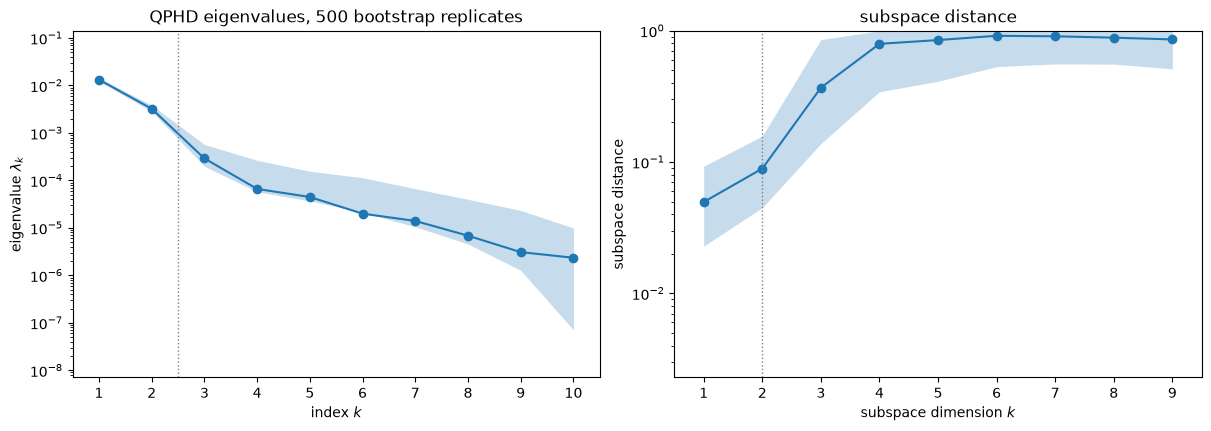

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
ac.plotting.plot_eigenvalues(sub, interval='percentile', ax=ax[0])
ac.plotting.plot_subspace_errors(sub, interval='percentile', ax=ax[1])
ax[0].set_title('QPHD eigenvalues, 500 bootstrap replicates')
ax[1].set_title('subspace distance')
plt.close(fig)
fig

Left: eigenvalues with 95 % bootstrap bands; right: subspace distances. The drop after $\lambda_2$ and the
jump of the distance between $n$ = 2 (0.089) and $n$ = 3 (0.368) both point to two active directions.

w1: [-0.018  0.1    0.062 -0.921 -0.023 -0.041 -0.176 -0.123 -0.297 -0.037]
w2: [-0.005  0.083  0.514  0.331  0.006 -0.017 -0.179 -0.508 -0.573  0.015]
share of |w|^2 on c1, c5, d1, d5: w1 0.0039, w2 0.0006


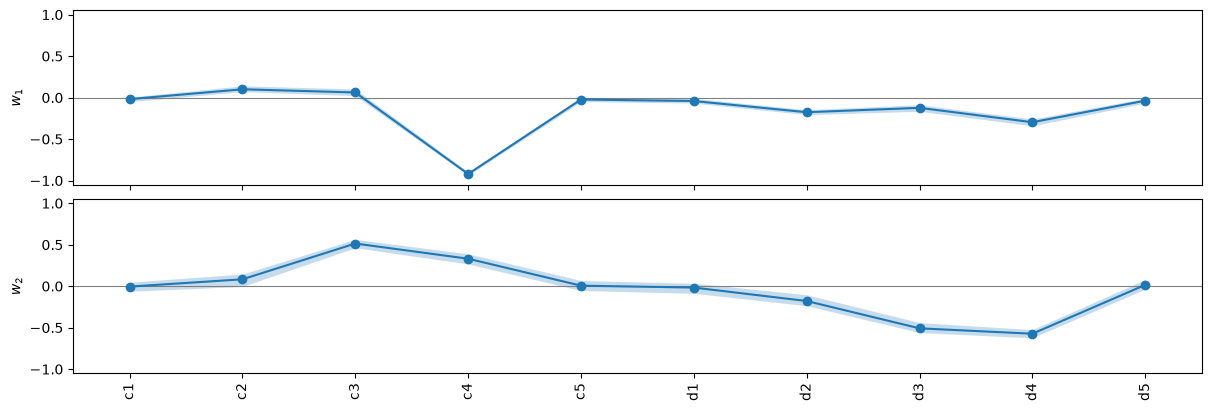

In [10]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=NAMES, interval='percentile',
                                        figsize=(12, 4))
print('w1:', np.round(sub.W[:, 0], 3))
print('w2:', np.round(sub.W[:, 1], 3))
share = (sub.W[[0, 4, 5, 9], :2]**2).sum(0)
print(f'share of |w|^2 on c1, c5, d1, d5: w1 {share[0]:.4f}, w2 {share[1]:.4f}')
plt.close(fig)
fig

$w_1$ is dominated by $c_4$ (−0.921), with $d_4$ (−0.297) and $d_2$ (−0.176): lift at the end of the run
falls when the upper surface is raised past mid-chord ($r_4$ peaks at $\xi$ = 0.6) and when the lower
surface is lowered. $w_2$ combines $c_3$ (0.514) and $c_4$ (0.331) with $d_3$ (−0.508) and $d_4$
(−0.573), a camber-like change (upper surface up, lower surface up) over the middle of the chord. The four
weights of the small shape functions carry 0.0039 of $|w_1|^2$ and 0.0006 of $|w_2|^2$.

corr(f, y1) = 0.861, corr(f, y2) = 0.337


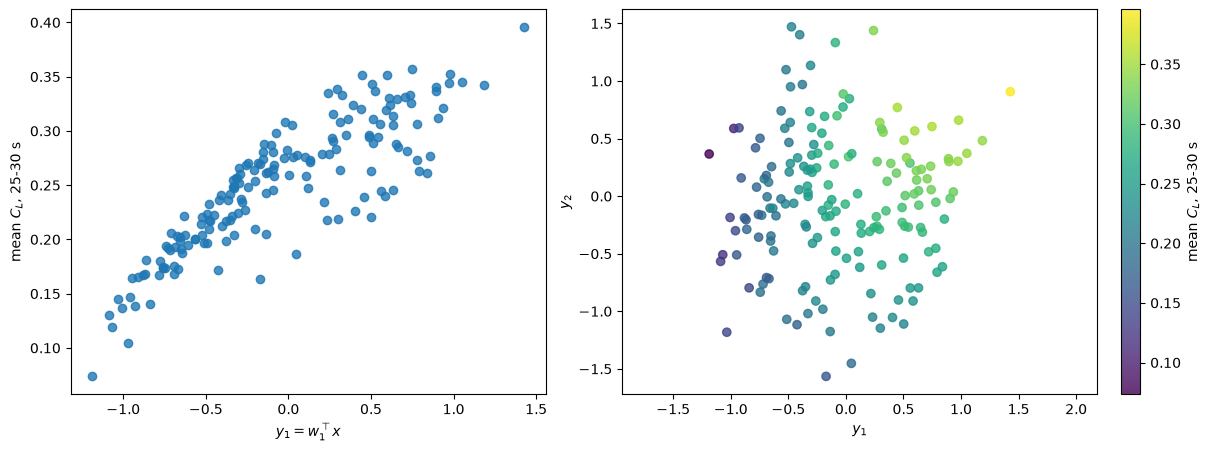

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, ax=ax[0], qoi_label='mean $C_L$, 25-30 s')
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, ax=ax[1], qoi_label='mean $C_L$, 25-30 s')
Y = Z @ sub.W[:, :2]
print(f'corr(f, y1) = {np.corrcoef(f, Y[:, 0])[0, 1]:.3f}, corr(f, y2) = {np.corrcoef(f, Y[:, 1])[0, 1]:.3f}')
plt.close(fig)
fig

Signs: each eigenvector is oriented so that the QoI increases with its active variable (`ac.orient`, by
covariance), the rule of this notebook since the paper shows no eigenvectors for a steady-state quantity.
Left: the mean lift against $y_1$ is monotone but spread (correlation 0.861); right: colouring the
$(y_1, y_2)$ plane by the mean lift shows the remaining variation along $y_2$ (correlation 0.337).

### Choosing the dimension

The next cell fits polynomials in the first $n$ QPHD variables and reports their leave-one-out $R^2$ (the
directions held fixed, which is optimistic), then a 10-fold cross-validation in which the QPHD subspace is
refitted in every fold.

In [12]:
print('leave-one-out R^2 of polynomial surrogates on the first n QPHD variables (directions fixed):')
print('  n   degree 1  degree 2  degree 3')
LOO = {}
for n in (1, 2, 3):
    row = []
    for deg in (1, 2, 3):
        s = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, n), kind='poly', degree=deg)
        LOO[n, deg] = s.loo_r_squared
        row.append(f'{s.loo_r_squared:8.4f}')
    print(f'  {n}  ' + '  '.join(row))
full2 = ac.fit_surrogate(X=X, f=f, subspace=None, space=space, kind='poly', degree=2)
full1 = ac.fit_surrogate(X=X, f=f, subspace=None, space=space, kind='poly', degree=1)
print(f'all 10 inputs: linear {full1.loo_r_squared:.4f}, full quadratic (66 terms) {full2.loo_r_squared:.4f}')

# Honest check: 10-fold cross-validation that refits the QPHD subspace and the quadratic in every fold.
rng = np.random.default_rng(SEED)
folds = np.array_split(rng.permutation(M), 10)
pred = {1: np.empty(M), 2: np.empty(M), 3: np.empty(M)}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.AccuracyWarning)
    for te in folds:
        tr = np.setdiff1d(np.arange(M), te)
        s_tr = ac.active_subspace(space=space, X=X[tr], f=f[tr], estimator='qphd', n=3)
        for n in (1, 2, 3):
            g = ac.fit_surrogate(X=X[tr], f=f[tr], subspace=ac.with_dimension(s_tr, n), kind='poly', degree=2)
            pred[n][te] = ac.predict(g, X[te]).ravel()
CV = {n: 1 - np.sum((f - p)**2) / np.sum((f - f.mean())**2) for n, p in pred.items()}
print('10-fold CV R^2, subspace refitted per fold, quadratic in n variables:',
      ', '.join(f'n = {n}: {v:.4f}' for n, v in CV.items()))

leave-one-out R^2 of polynomial surrogates on the first n QPHD variables (directions fixed):
  n   degree 1  degree 2  degree 3
  1    0.7357    0.7637    0.7809
  2    0.8269    0.9708    0.9687
  3    0.8251    0.9855    0.9862
all 10 inputs: linear 0.8115, full quadratic (66 terms) 0.9760
10-fold CV R^2, subspace refitted per fold, quadratic in n variables: n = 1: 0.7621, n = 2: 0.9647, n = 3: 0.9778


One variable leaves much unexplained (quadratic LOO $R^2$ 0.7637; 10-fold 0.7621). Two variables reach
0.9708 (10-fold 0.9647), close to the full quadratic in all 10 inputs (0.9760). A third adds little
(0.9855; 10-fold 0.9778). **The notebook uses $n$ = 2**: it follows the largest eigenvalue ratio
($\lambda_2/\lambda_3$ = 11.14), the jump of the subspace distance after $n$ = 2, and the jump of the
cross-validated $R^2$ from 0.7621 to 0.9647; the eigenvalues beyond the second hold 0.0263 of the total.
The next ratio, $\lambda_3/\lambda_4$ = 4.38, is comparable to $\lambda_1/\lambda_2$ = 4.12, and its
bootstrap interval is wide (1.26–6.35), so a three-dimensional subspace is a defensible alternative for
accuracy-critical use.

### Effect of the transient rule

The same estimator with the averaging window starting at other times $t_0$ (always ending at 30 s), and with
the instantaneous value at 30 s.

In [13]:
# Effect of the rule: start the averaging window at t0 instead of 25 s (end always 30 s), and the
# instantaneous value at 30 s. Each row: QoI statistics, QPHD ratios, and the distance of its 2-D subspace
# (and of its w1) from the chosen one.
print('   t0 [s]   mean    sd     l1/l2   l2/l3   dist(2-D)  |w1.w1(25 s)|  max|f - f(25 s)|')
rows = []
for t0 in (0.0, 0.05, 1.0, 5.0, 10.0, 15.0, 20.0, 25.0, 28.0):
    g = window_mean(t0)
    s = ac.active_subspace(space=space, X=X, f=g, estimator='qphd', n=2)
    e = s.eigenvalues
    dist = np.linalg.norm(W2q.T @ s.W[:, 2:], 2)
    rows.append((t0, g.mean(), g.std(ddof=1), e[0] / e[1], e[1] / e[2], dist, abs(s.W[:, 0] @ sub.W[:, 0]),
                 np.abs(g - f).max()))
    print('   {:5.2f}   {:.4f}  {:.4f}  {:6.2f}  {:6.2f}    {:.3f}       {:.3f}         {:.4f}'.format(*rows[-1]))
g = LIFT[:, -1]
s = ac.active_subspace(space=space, X=X, f=g, estimator='qphd', n=2)
e = s.eigenvalues
print(f'C_L(30 s): l1/l2 {e[0] / e[1]:.2f}, l2/l3 {e[1] / e[2]:.2f}, '
      f'dist(2-D) {np.linalg.norm(W2q.T @ s.W[:, 2:], 2):.3f}, |w1.w1(25 s)| {abs(s.W[:, 0] @ sub.W[:, 0]):.3f}')

   t0 [s]   mean    sd     l1/l2   l2/l3   dist(2-D)  |w1.w1(25 s)|  max|f - f(25 s)|
    0.00   0.2832  0.0379    2.49   19.20    0.108       0.614         0.1416
    0.05   0.2836  0.0379    2.48   18.56    0.102       0.613         0.1427
    1.00   0.2870  0.0389    2.45   18.69    0.095       0.623         0.1439


    5.00   0.2891  0.0421    2.27   18.16    0.083       0.738         0.1316
   10.00   0.2768  0.0473    2.38   15.47    0.066       0.915         0.0942
   15.00   0.2587  0.0542    3.26   12.96    0.032       0.993         0.0410
   20.00   0.2518  0.0579    3.89   11.72    0.012       1.000         0.0127
   25.00   0.2497  0.0592    4.12   11.14    0.000       1.000         0.0000
   28.00   0.2492  0.0595    4.17   10.96    0.005       1.000         0.0041
C_L(30 s): l1/l2 4.18, l2/l3 10.87, dist(2-D) 0.008, |w1.w1(25 s)| 1.000


The rule matters when the window includes the start-up: averaging over the whole run ($t_0$ = 0, including
the spikes) gives a QoI that differs from the chosen one by up to 0.1416 and a first direction at
$|w_1\cdot w_1(25\,\text{s})|$ = 0.614 from the chosen one, and $t_0$ = 5 s still gives 0.738. The
spikes themselves matter little (0 and 0.05 s give nearly the same rows): what changes the answer is the
development phase of 1–15 s. From $t_0$ = 20 s on, the QoI moves by at most 0.0127, the 2-D subspace by at
most 0.012 and the ratios stay at 3.89–4.17 and 10.96–11.72; $C_L$(30 s) gives the same subspace (distance
0.008). The conclusion, $n$ = 2 with the directions above, does not depend on where the window starts after
20 s.

## Comparison with the paper's dynamic active subspace

The paper shows, for $C_L$ at $t$ = 6, 10, 14 and 18 s, the first eigenvector and a one-dimensional
summary plot (Figs. 6–9, pp. 12–14), computed with ATHENA (Fig. 2, p. 8). The repository's `dyas.py` uses
ATHENA's local-linear method with 1000 bootstrap replicates on the first 70 runs (the training set) and
column 1000·t of the lift array. The paper prints no eigenvalues. Below, the components read from the figures are compared
with local linear gradients on the same 70 runs and with QPHD on all 170. **Coordinates:** `dyas.py`
normalizes the stored lower-surface weights, which are $-d_i$; the figures' "$d_i$" axis is therefore
$-d_i$, and the figure values are sign-flipped for $d$ before the comparison. Eigenvectors are oriented to
the figures (`ac.orient`, by reference).

In [14]:
# The paper's dynamic active subspace (Figs. 6-9): first eigenvector of C_L at t = 6, 10, 14, 18 s.
# Values read from the right panels of the figures (+-0.02). The figures' d axis is the stored parBot,
# i.e. -d (the authors' dyas.py normalizes parBot in [-0.03, 0]); FIG_D converts them to the d of Eq. 5.
FIG = {6: [0.00, 0.15, 0.51, 0.51, 0.01, 0.01, 0.21, 0.41, 0.50, 0.02],
       10: [0.00, 0.13, 0.51, 0.49, 0.01, 0.01, 0.20, 0.43, 0.51, 0.02],
       14: [0.00, 0.15, 0.56, 0.03, 0.00, 0.02, 0.27, 0.44, 0.64, 0.03],
       18: [-0.03, 0.11, 0.40, -0.55, -0.02, 0.01, 0.25, 0.36, 0.58, 0.04]}
FLIP = np.r_[np.ones(5), -np.ones(5)]
DYAS = {}
for tt, v in FIG.items():
    ref = FLIP * np.array(v)
    ref /= np.linalg.norm(ref)
    ft = LIFT[:, 1000 * tt]                      # column 1000 t, as in dyas.py (time step 1000 t + 1)
    g70 = ac.local_linear_gradients(X=X[TRAIN], f=ft[TRAIN], space=space)
    s70 = ac.orient(ac.active_subspace(grads=g70, estimator='as', n=1), by='reference', reference=ref[:, None])
    s170 = ac.orient(ac.active_subspace(space=space, X=X, f=ft, estimator='qphd', n=1),
                     by='reference', reference=ref[:, None])
    DYAS[tt] = (ref, s70, s170)
    e70, e170 = s70.eigenvalues, s170.eigenvalues
    print(f't = {tt:2d} s  (Fig. {dict(zip((6, 10, 14, 18), (6, 7, 8, 9)))[tt]}; figure values in d coordinates)')
    print('   figure     ', np.round(FLIP * np.array(v), 2))
    print('   LL, 70 runs', np.round(s70.W[:, 0], 2), f' |w.w_fig| {abs(s70.W[:, 0] @ ref):.3f}',
          f' l1/l2 {e70[0] / e70[1]:.1f}')
    print('   QPHD, 170  ', np.round(s170.W[:, 0], 2), f' |w.w_fig| {abs(s170.W[:, 0] @ ref):.3f}',
          f' l1/l2 {e170[0] / e170[1]:.1f}')

t =  6 s  (Fig. 6; figure values in d coordinates)
   figure      [ 0.    0.15  0.51  0.51  0.01 -0.01 -0.21 -0.41 -0.5  -0.02]
   LL, 70 runs [-0.01  0.14  0.5   0.51  0.01 -0.01 -0.21 -0.42 -0.5  -0.02]  |w.w_fig| 1.000  l1/l2 2344.6
   QPHD, 170   [-0.    0.15  0.5   0.51  0.01 -0.01 -0.21 -0.42 -0.5  -0.02]  |w.w_fig| 1.000  l1/l2 827.3
t = 10 s  (Fig. 7; figure values in d coordinates)
   figure      [ 0.    0.13  0.51  0.49  0.01 -0.01 -0.2  -0.43 -0.51 -0.02]
   LL, 70 runs [-0.01  0.13  0.51  0.5   0.   -0.01 -0.2  -0.42 -0.5  -0.02]  |w.w_fig| 1.000  l1/l2 2248.3
   QPHD, 170   [-0.    0.14  0.51  0.5   0.   -0.   -0.2  -0.42 -0.51 -0.02]  |w.w_fig| 1.000  l1/l2 843.5
t = 14 s  (Fig. 8; figure values in d coordinates)
   figure      [ 0.    0.15  0.56  0.03  0.   -0.02 -0.27 -0.44 -0.64 -0.03]
   LL, 70 runs [-0.05  0.15  0.57  0.04 -0.   -0.02 -0.27 -0.44 -0.62 -0.02]  |w.w_fig| 0.998  l1/l2 79.7
   QPHD, 170   [-0.    0.16  0.54  0.08 -0.   -0.02 -0.28 -0.44 -0.63 -0.03]  |w

At 6 and 10 s all three agree to within the reading accuracy ($|w\cdot w_{fig}|$ = 1.000), and the
eigenvalue ratio $\lambda_1/\lambda_2$ is in the thousands for local linear gradients (2344.6, 2248.3) and
hundreds for QPHD (827.3, 843.5): $C_L$ is then nearly a linear function of one combination of the weights,
as the straight-line summary plots of Figs. 6–7 show. At 14 s the agreement is 0.998 and 0.999. At 18 s the
local linear estimate on the 70 training runs matches the figure (0.996, $c_4$ = −0.55 as in Fig. 9), while
QPHD on 170 runs gives a different first direction (0.948, $c_4$ = −0.78) with a small first ratio (2.6): by
18 s the one-dimensional picture has broken down, as the paper says (p. 13), and the leading direction
depends on the estimator.

**What the signs mean.** In the figures the $c_3, c_4$ and the "$d_3, d_4$" components have the same sign,
and the paper reads this as "higher values of lift can be obtained by increasing the airfoil thickness in
the mid-chord region" (p. 12). In the coordinates of Eq. 5 the $d$ components have the opposite sign: the
correlations below are checked directly on the data, with no subspace involved.

In [15]:
# What the signs mean: correlation of C_L with each weight (positive d lowers the lower surface, Eq. 5).
for tt in (10, 18):
    r = [np.corrcoef(X[:, j], LIFT[:, 1000 * tt])[0, 1] for j in range(m)]
    print(f'corr(C_L({tt} s), input): ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(NAMES, r)))
r = [np.corrcoef(X[:, j], f)[0, 1] for j in range(m)]
print('corr(QoI, input):        ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(NAMES, r)))

corr(C_L(10 s), input): c1 -0.15, c2 +0.07, c3 +0.45, c4 +0.48, c5 -0.03, d1 +0.02, d2 -0.22, d3 -0.41, d4 -0.60, d5 +0.06
corr(C_L(18 s), input): c1 -0.07, c2 +0.05, c3 +0.30, c4 -0.50, c5 +0.10, d1 -0.05, d2 -0.24, d3 -0.42, d4 -0.55, d5 +0.00
corr(QoI, input):        c1 -0.03, c2 +0.06, c3 +0.18, c4 -0.67, c5 +0.11, d1 -0.06, d2 -0.22, d3 -0.35, d4 -0.43, d5 -0.02


At 10 s $C_L$ grows with $c_3$ (+0.45) and $c_4$ (+0.48) and falls with $d_3$ (−0.41) and $d_4$ (−0.60):
lift increases when the mid-chord upper surface is raised *and* the lower surface is raised (smaller $d$),
which is an increase of camber, not of thickness (a thicker section has larger $c$ and larger $d$). The
paper's reading of the $d$ components holds only for the stored sign. For the steady QoI $C_L$ falls with
$c_4$ (−0.67) and with $d_4$ (−0.43), consistent with $w_1$ above, and with the paper's observation that
the $c_4$ component changes sign between 14 and 18 s (p. 13).

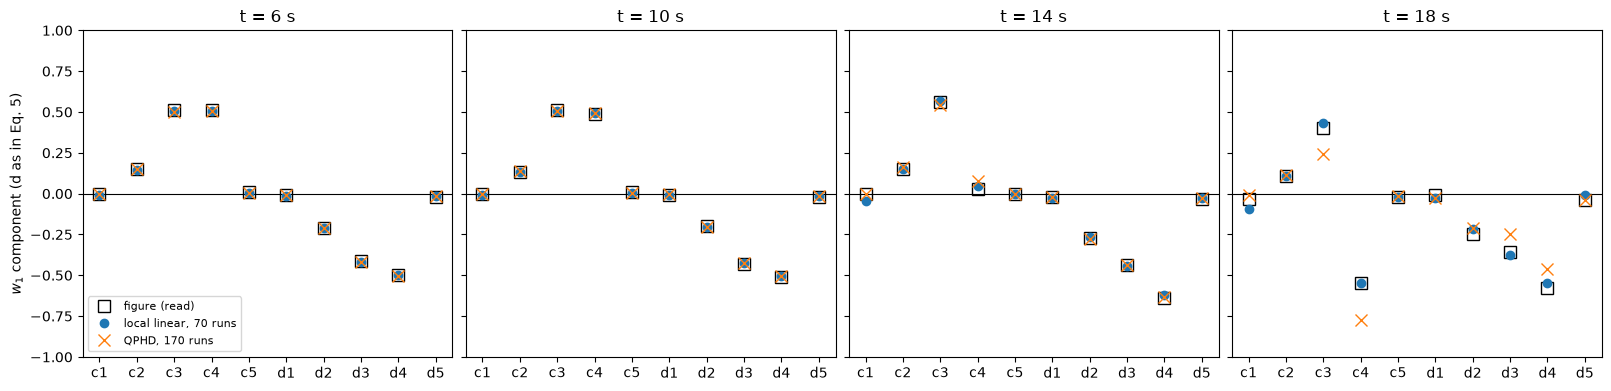

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True, sharey=True)
for a, (tt, (ref, s70, s170)) in zip(axs, DYAS.items()):
    a.axhline(0, color='k', lw=0.8)
    a.plot(range(m), ref * np.linalg.norm(FLIP * np.array(FIG[tt])), 'ks', mfc='none', ms=8, label='figure (read)')
    a.plot(range(m), s70.W[:, 0], 'o', label='local linear, 70 runs')
    a.plot(range(m), s170.W[:, 0], 'x', ms=8, label='QPHD, 170 runs')
    a.set_xticks(range(m), NAMES)
    a.set_title(f't = {tt} s')
    a.set_ylim(-1, 1)
axs[0].set_ylabel('$w_1$ component (d as in Eq. 5)')
axs[0].legend(fontsize=8, loc='lower left')
plt.close(fig)
fig

Squares: figure values (read, in the $d$ of Eq. 5); circles: local linear gradients on the 70 training runs;
crosses: QPHD on 170 runs. The four small-shape-function weights $c_1, c_5, d_1, d_5$ stay near zero at all
four times, as the paper reports (p. 13); the shape-function amplitudes in the model section explain why.

## Comparison with the paper

| quantity | paper (page) | this notebook |
|---|---|---|
| runs, inputs | 70 training + 100 test, $m$ = 10, $D = [0, 0.03]^{10}$ (pp. 9, 14) | 170 rows, all in $D$; independent-uniform-like, not a Latin hypercube |
| sample of Fig. 4 | μ printed in the caption (p. 10) | row 1 (training), values truncated, $d$ listed first |
| $w_1$ at 6 s, 10 s | Figs. 6–7 (p. 12) | $|w\cdot w_{fig}|$ 1.000 (local linear, 70 runs; QPHD, 170 runs) |
| $w_1$ at 14 s | Fig. 8 (p. 13) | 0.998 (local linear), 0.999 (QPHD) |
| $w_1$ at 18 s, $c_4$ component | Fig. 9 (p. 14): $c_4 \approx$ −0.55 | local linear −0.55 (0.996); QPHD −0.78 (0.948) |
| eigenvalues | not reported | 6 s: $\lambda_1/\lambda_2$ 2344.6 (LL), 827.3 (QPHD); 18 s: 17.6, 2.6 |
| inactive weights | $c_1, c_5, d_1, d_5$ almost zero (p. 13) | share of $|w|^2$ on them 0.0039 ($w_1$), 0.0006 ($w_2$) for the mean lift |
| sign of the $d$ components | read as thickness (p. 12) | figures use $-d$; in Eq. 5's $d$ the effect is camber |
| dimension | 1-D shown; "higher dimensional active subspaces are required" near steady state (p. 13) | mean lift 25–30 s: $n$ = 2 ($\lambda_2/\lambda_3$ = 11.14) |
| quantity of interest at steady state | $C_L$ at 20 s and DMD forecast to 30 s (pp. 14–16) | mean $C_L$ over 25–30 s (this data set's choice) |
| reduced regression | GPR error 0.042 (6 weights) vs 0.087 (10) at regime (p. 16) | not reproduced (no GPR here); quadratic in 2 active variables LOO $R^2$ 0.9708 |
| reference $C_L$ of the NACA 4412 | 0.355 (p. 9) | not in the data (no undeformed run) |

## References

- M. Tezzele, N. Demo, G. Stabile, A. Mola, G. Rozza. Enhancing CFD predictions in shape design problems by
  model and parameter space reduction. *Advanced Modeling and Simulation in Engineering Sciences* 7:40, 2020.
  [doi:10.1186/s40323-020-00177-y](https://doi.org/10.1186/s40323-020-00177-y). Data and scripts:
  github.com/mtezzele/MORtech-2019-Special-Issue (commit ec05216, 2020-05-04).
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
- R. M. Hicks, P. A. Henne. Wing design by numerical optimization. *Journal of Aircraft* 15(7):407–412, 1978.
  [doi:10.2514/3.58379](https://doi.org/10.2514/3.58379)
- P. Spalart, S. Allmaras. A one-equation turbulence model for aerodynamic flows. 30th Aerospace Sciences
  Meeting and Exhibit, Reno, 1992. [doi:10.2514/6.1992-439](https://doi.org/10.2514/6.1992-439)

## Acknowledgments

The paper's funding statement (p. 17): an industrial Ph.D. grant sponsored by Fincantieri S.p.A.; the project
UBE2 "Underwater blue efficiency 2" funded by Regione FVG, POR-FESR 2014–2020; and the European Research
Council, H2020 ERC CoG 2015 AROMA-CFD project 681447 (P.I. G. Rozza).

In [17]:
print(f'notebook run time {time.perf_counter() - t_start:.0f} s')

notebook run time 7 s
